# Cars price regression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Гипотезы

- Дерево с подобранной глубиной достигнет валидационного MAE ниже чем линейная регрессия, так как цена опирается на нелинейные соотношения
- Если убрать признаки цвета интерьера и экстерьера, валидационная MAE изменится в пределах 2%, так как эти фичи не так сильно влияют на стоимость
- Предсказывать `log(1 + p)` где `p` это цена даст валидацонное MAE ниже чем просто предсказание цены, так как очень дорогие машины не будут так сильно влиять на модель
- Дерево без ограничений на глубину заоверфиттится больше чем средней глубины, без ограничений MAE будет меньше на трейне, но больше на тесте
- Если достать из описания мотора доп параметры (например, лошадиные силы, количество цилиндров и тд), то валидационное MAE уменьшится
- Добавление бренда и модели в модель даст меньший валидационный MAE чем без них

## Загрузка данных и проверки

In [2]:
df = pd.read_csv("used_cars.csv")
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [3]:
df.shape

(4009, 12)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   brand         4009 non-null   str  
 1   model         4009 non-null   str  
 2   model_year    4009 non-null   int64
 3   milage        4009 non-null   str  
 4   fuel_type     3839 non-null   str  
 5   engine        4009 non-null   str  
 6   transmission  4009 non-null   str  
 7   ext_col       4009 non-null   str  
 8   int_col       4009 non-null   str  
 9   accident      3896 non-null   str  
 10  clean_title   3413 non-null   str  
 11  price         4009 non-null   str  
dtypes: int64(1), str(11)
memory usage: 376.0 KB


In [5]:
df.isna().sum().sort_values(ascending=False)

clean_title     596
fuel_type       170
accident        113
brand             0
milage            0
model_year        0
model             0
engine            0
ext_col           0
transmission      0
int_col           0
price             0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.nunique()

brand             57
model           1898
model_year        34
milage          2818
fuel_type          7
engine          1146
transmission      62
ext_col          319
int_col          156
accident           2
clean_title        1
price           1569
dtype: int64

In [8]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
model_year,4009.0,2015.51559,6.104816,1974.0,2012.0,2017.0,2020.0,2024.0


In [9]:
display(df.select_dtypes(include=["object", "string"]).describe().T)

,count,unique,top,freq
brand,4009,57,Ford,386
model,4009,1898,M3 Base,30
milage,4009,2818,"110,000 mi.",16
fuel_type,3839,7,Gasoline,3309
engine,4009,1146,2.0L I4 16V GDI DOHC Turbo,52
transmission,4009,62,A/T,1037
ext_col,4009,319,Black,905
int_col,4009,156,Black,2025
accident,3896,2,None reported,2910
clean_title,3413,1,Yes,3413


In [10]:
for col in ["fuel_type", "transmission", "accident", "clean_title"]:
    print(df[col].value_counts(dropna=False))
    print()

fuel_type
Gasoline          3309
Hybrid             194
NaN                170
E85 Flex Fuel      139
Diesel             116
–                   45
Plug-In Hybrid      34
not supported        2
Name: count, dtype: int64

transmission
A/T                                  1037
8-Speed A/T                           406
Transmission w/Dual Shift Mode        398
6-Speed A/T                           362
6-Speed M/T                           248
                                     ... 
7-Speed DCT Automatic                   1
9-Speed Automatic with Auto-Shift       1
SCHEDULED FOR OR IN PRODUCTION          1
6 Speed Mt                              1
8-Speed Manual                          1
Name: count, Length: 62, dtype: int64

accident
None reported                             2910
At least 1 accident or damage reported     986
NaN                                        113
Name: count, dtype: int64

clean_title
Yes    3413
NaN     596
Name: count, dtype: int64



### Выводы первичного анализа

- Датасет содержит 4009 строк и 12 столбцов
- Цена и пробег записаны строками с символами валюты, разделителями и единицами измерения. Их необходимо преобразовать в числа
- Пропуски присутствуют в clean_title, fuel_type и accident
- В fuel_type также встречается значение `-`
- Полных дубликатов не обнаружено
- В transmission встречаются разные форматы названий и подозрительное значение SCHEDULED FOR OR IN PRODUCTION
- Признак model содержит 1898 уникальных значений: многие модели представлены небольшим числом наблюдений.

## Подчистка данных

In [11]:
df_raw = pd.read_csv("used_cars.csv")
df = df_raw.copy()
df["price"] = pd.to_numeric(df["price"].str.replace("$", "", regex=False).str.replace(",", "", regex=False))
df["milage"] = pd.to_numeric(df["milage"].str.replace(" mi.", "", regex=False).str.replace(",", "", regex=False))
df["fuel_type"] = df["fuel_type"].replace("–", np.nan)
df["transmission"] = df["transmission"].replace("–", np.nan)
df["engine"] = df["engine"].replace("–", np.nan)

In [12]:
display(df[["price", "milage", "model_year"]].describe())
print(df["transmission"].value_counts().to_string())
display(df.loc[(df["price"] <= 0) | (df["milage"] < 0), ["brand", "model", "price", "milage"]])

,price,milage,model_year
count,4.009000e+03,4009.000000,4009.000000
mean,4.455319e+04,64717.551010,2015.515590
std,7.871064e+04,52296.599459,6.104816
min,2.000000e+03,100.000000,1974.000000
25%,1.720000e+04,23044.000000,2012.000000
50%,3.100000e+04,52775.000000,2017.000000
75%,4.999000e+04,94100.000000,2020.000000
max,2.954083e+06,405000.000000,2024.000000


transmission
A/T                                                                 1037
8-Speed A/T                                                          406
Transmission w/Dual Shift Mode                                       398
6-Speed A/T                                                          362
6-Speed M/T                                                          248
Automatic                                                            237
7-Speed A/T                                                          209
8-Speed Automatic                                                    176
10-Speed A/T                                                         119
5-Speed A/T                                                           86
9-Speed A/T                                                           74
6-Speed Automatic                                                     73
4-Speed A/T                                                           72
1-Speed A/T                           

,brand,model,price,milage


## Train/test split

In [13]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
train_df, test_df = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (3207, 12)
Test: (802, 12)


## Исследование обучающей выборки

In [14]:
display(
    train_df[["price", "milage", "model_year"]]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    .T
)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
price,3207.0,43125.756782,51204.516050,2000.0,4000.00,7030.0,17050.0,31300.0,49999.0,109970.0,259470.0,749950.0
milage,3207.0,64942.199563,52433.516741,100.0,816.24,3733.6,23319.5,53500.0,93985.5,165317.8,224940.0,405000.0
model_year,3207.0,2015.557842,6.032533,1974.0,1997.06,2004.0,2012.0,2017.0,2020.0,2023.0,2023.0,2024.0


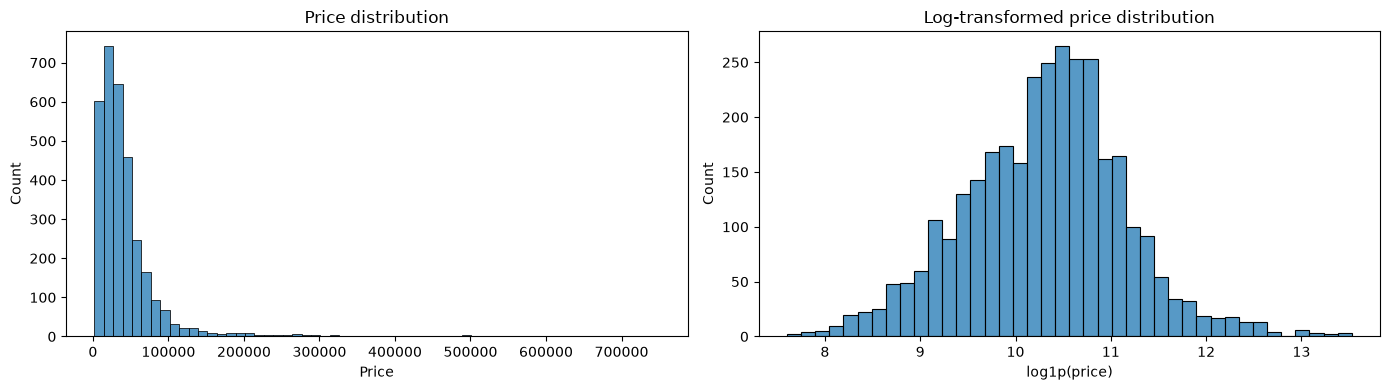

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(train_df["price"], bins=60, ax=axes[0])
axes[0].set_title("Price distribution")
axes[0].set_xlabel("Price")

sns.histplot(np.log1p(train_df["price"]), bins=40, ax=axes[1])
axes[1].set_title("Log-transformed price distribution")
axes[1].set_xlabel("log1p(price)")

plt.tight_layout()
plt.show()

In [16]:
columns = ["brand", "model", "model_year", "milage", "fuel_type", "engine", "price"]

display(train_df.nlargest(10, "price")[columns])
display(train_df.nsmallest(10, "price")[columns])
display(train_df.nlargest(10, "milage")[columns])

,brand,model,model_year,milage,fuel_type,engine,price
1356,Lamborghini,Aventador SVJ Base,2021,6987,Gasoline,6.5L V12 48V MPFI DOHC,749950
624,Rolls-Royce,Cullinan,2022,398,Gasoline,6.7L V12 48V GDI DOHC Twin Turbo,695000
979,Lamborghini,Aventador SVJ Base,2019,6929,Gasoline,759.0HP 6.5L 12 Cylinder Engine Gasoline Fuel,649999
1615,Rolls-Royce,Phantom,2023,1560,NaN,NaN,599995
1508,Rolls-Royce,Phantom,2018,7585,Gasoline,6.8L V12 48V GDI DOHC Twin Turbo,599000
3655,Lamborghini,Aventador S Base,2018,5858,Gasoline,729.0HP 6.5L 12 Cylinder Engine Gasoline Fuel,491836
1148,Porsche,911 R,2016,719,Gasoline,4.0L H6 24V GDI DOHC,489000
304,Rolls-Royce,Phantom Drophead Coupe Drophead,2013,2958,Gasoline,6.8L V12 48V GDI DOHC,488880
2133,Cadillac,Escalade ESV Sport,2021,4283,Gasoline,6.2L V8 16V GDI OHV,479995
1597,Ferrari,812 Superfast Base,2020,1575,Gasoline,788.0HP 6.5L 12 Cylinder Engine Gasoline Fuel,469900


,brand,model,model_year,milage,fuel_type,engine,price
425,Lincoln,Aviator Luxury,2005,140000,Gasoline,302.0HP 4.6L 8 Cylinder Engine Gasoline Fuel,2000
89,Subaru,Forester 2.5 X,2004,210703,Gasoline,165.0HP 2.5L 4 Cylinder Engine Gasoline Fuel,2300
1292,BMW,323 Ci,2000,177700,Gasoline,170.0HP 2.5L Straight 6 Cylinder Engine Gasoli...,2500
626,Pontiac,Firebird Base,1999,158000,Gasoline,200.0HP 3.8L V6 Cylinder Engine Gasoline Fuel,2500
3907,Toyota,Camry Solara SLE V6,2000,245000,Gasoline,200.0HP 3.0L V6 Cylinder Engine Gasoline Fuel,2500
3922,Mazda,Protege DX,1993,94200,NaN,NaN,2500
3595,Nissan,Altima 2.5 S,2003,189000,Gasoline,175.0HP 2.5L 4 Cylinder Engine Gasoline Fuel,2899
2012,Hyundai,Accent GL,2003,83000,Gasoline,104.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,2900
419,Honda,Civic LX,2003,160265,Gasoline,115.0HP 1.7L 4 Cylinder Engine Gasoline Fuel,3000
1629,Ford,Escape XLT,2007,133300,Gasoline,153.0HP 2.3L 4 Cylinder Engine Gasoline Fuel,3000


,brand,model,model_year,milage,fuel_type,engine,price
2764,Honda,Accord Sport,2013,405000,Gasoline,185.0HP 2.4L 4 Cylinder Engine Gasoline Fuel,6000
3348,Mercedes-Benz,Sprinter 2500,2016,399000,Diesel,188.0HP 3.0L V6 Cylinder Engine Diesel Fuel,24500
2175,Ford,Excursion Limited,2001,333361,Diesel,250.0HP 7.3L 8 Cylinder Engine Diesel Fuel,17000
31,Dodge,Ram 1500 Laramie Mega Cab,2006,300183,Gasoline,345.0HP 5.7L 8 Cylinder Engine Gasoline Fuel,10900
1145,GMC,Sierra 3500 SLE,2002,300000,Diesel,300.0HP 6.6L 8 Cylinder Engine Diesel Fuel,5000
3118,Dodge,Dakota Sport,1997,285000,Gasoline,230.0HP 5.2L 8 Cylinder Engine Gasoline Fuel,6399
3747,Ford,F-150 Lariat SuperCrew,2004,271000,Gasoline,300.0HP 5.4L 8 Cylinder Engine Gasoline Fuel,9500
2558,Toyota,Land Cruiser Base,2010,269885,Gasoline,381.0HP 5.7L 8 Cylinder Engine Gasoline Fuel,22500
3158,Toyota,4Runner 4WD,1999,267000,Gasoline,150.0HP 2.7L 4 Cylinder Engine Gasoline Fuel,8000
3601,Toyota,Land Cruiser Base,2000,265000,Gasoline,230.0HP 4.7L 8 Cylinder Engine Gasoline Fuel,15500


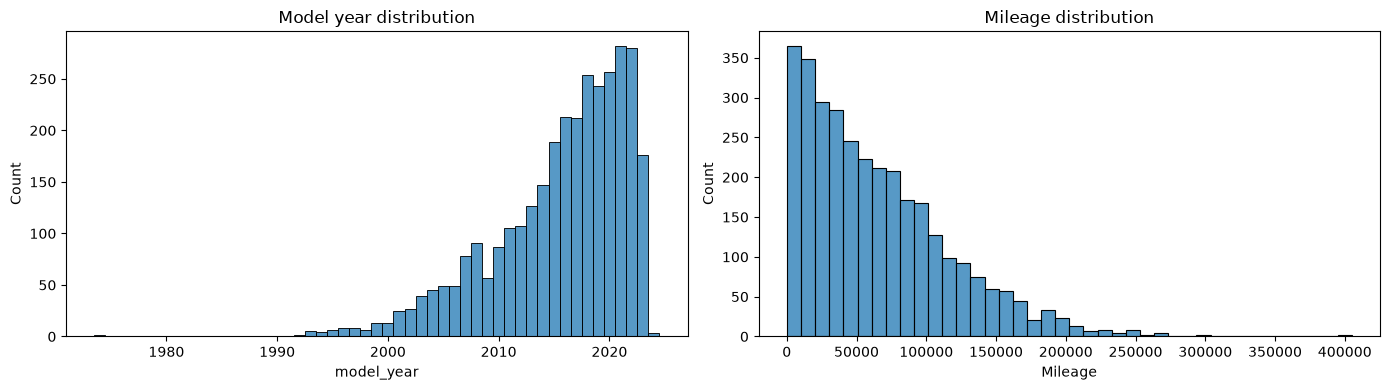

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(data=train_df, x="model_year", discrete=True, ax=axes[0])
axes[0].set_title("Model year distribution")

sns.histplot(data=train_df, x="milage", bins=40, ax=axes[1])
axes[1].set_title("Mileage distribution")
axes[1].set_xlabel("Mileage")

plt.tight_layout()
plt.show()

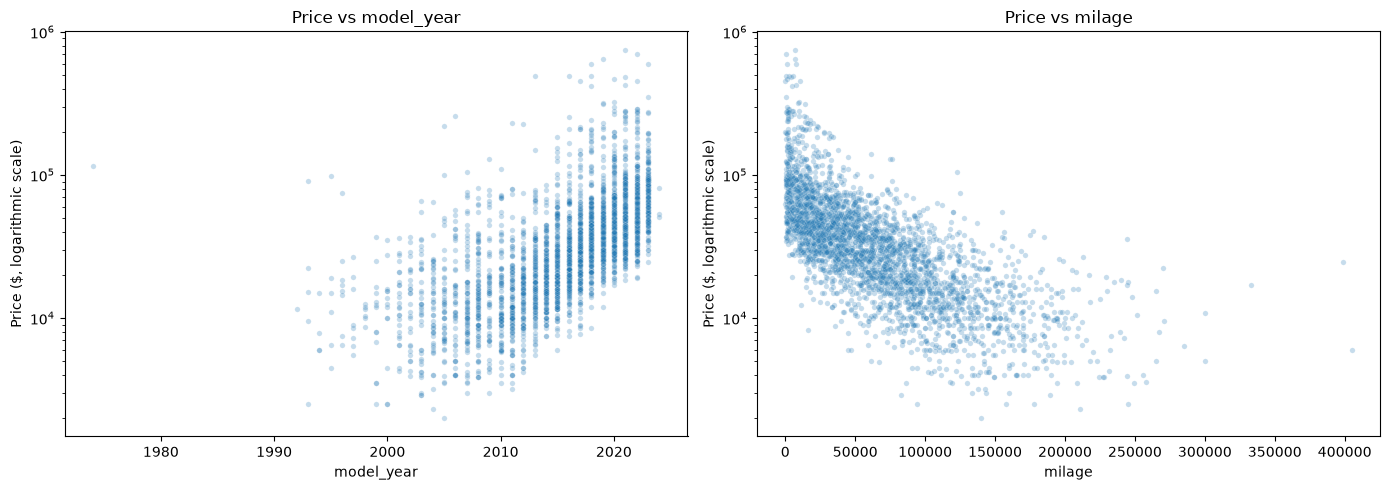

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, feature in zip(axes, ["model_year", "milage"]):
    sns.scatterplot(data=train_df, x=feature, y="price", s=15, alpha=0.25, ax=ax)
    ax.set_yscale("log")
    ax.set_ylabel("Price ($, logarithmic scale)")
    ax.set_title(f"Price vs {feature}")

plt.tight_layout()
plt.show()

,count,median_mileage,median_price
mileage_group,,,
"(99.999, 11191.0]",401,4900.0,73300.0
"(11191.0, 23319.5]",401,16919.0,49999.0
"(23319.5, 37000.0]",403,30176.0,42442.0
"(37000.0, 53500.0]",400,45000.0,36999.0
"(53500.0, 72257.75]",399,62377.0,27500.0
"(72257.75, 93985.5]",401,82849.0,21500.0
"(93985.5, 126820.0]",401,107800.0,15300.0
"(126820.0, 405000.0]",401,158000.0,10500.0


,count,median_price
model_year,,
1974,1,115000.0
1992,1,11500.0
1993,5,15300.0
1994,4,6950.0
1995,6,12999.5
1996,8,16249.5
1997,8,8750.0
1998,6,10900.0
1999,13,12000.0


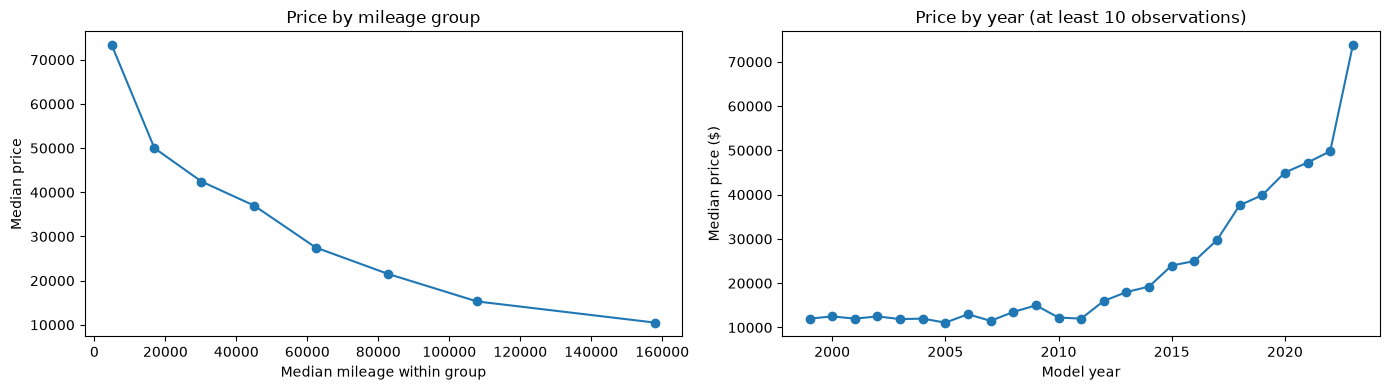

In [19]:
eda = train_df.copy()

eda["mileage_group"] = pd.qcut(eda["milage"], q=8, duplicates="drop")

mileage_summary = (
    eda.groupby("mileage_group", observed=True)
    .agg(
        count=("price", "size"),
        median_mileage=("milage", "median"),
        median_price=("price", "median"),
    )
)

year_summary = (
    eda.groupby("model_year")
    .agg(
        count=("price", "size"),
        median_price=("price", "median"),
    )
)

display(mileage_summary)
display(year_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(
    mileage_summary["median_mileage"],
    mileage_summary["median_price"],
    marker="o",
)
axes[0].set_xlabel("Median mileage within group")
axes[0].set_ylabel("Median price")
axes[0].set_title("Price by mileage group")

supported_years = year_summary.loc[year_summary["count"] >= 10]

axes[1].plot(
    supported_years.index,
    supported_years["median_price"],
    marker="o",
)
axes[1].set_xlabel("Model year")
axes[1].set_ylabel("Median price ($)")
axes[1].set_title("Price by year (at least 10 observations)")

plt.tight_layout()
plt.show()

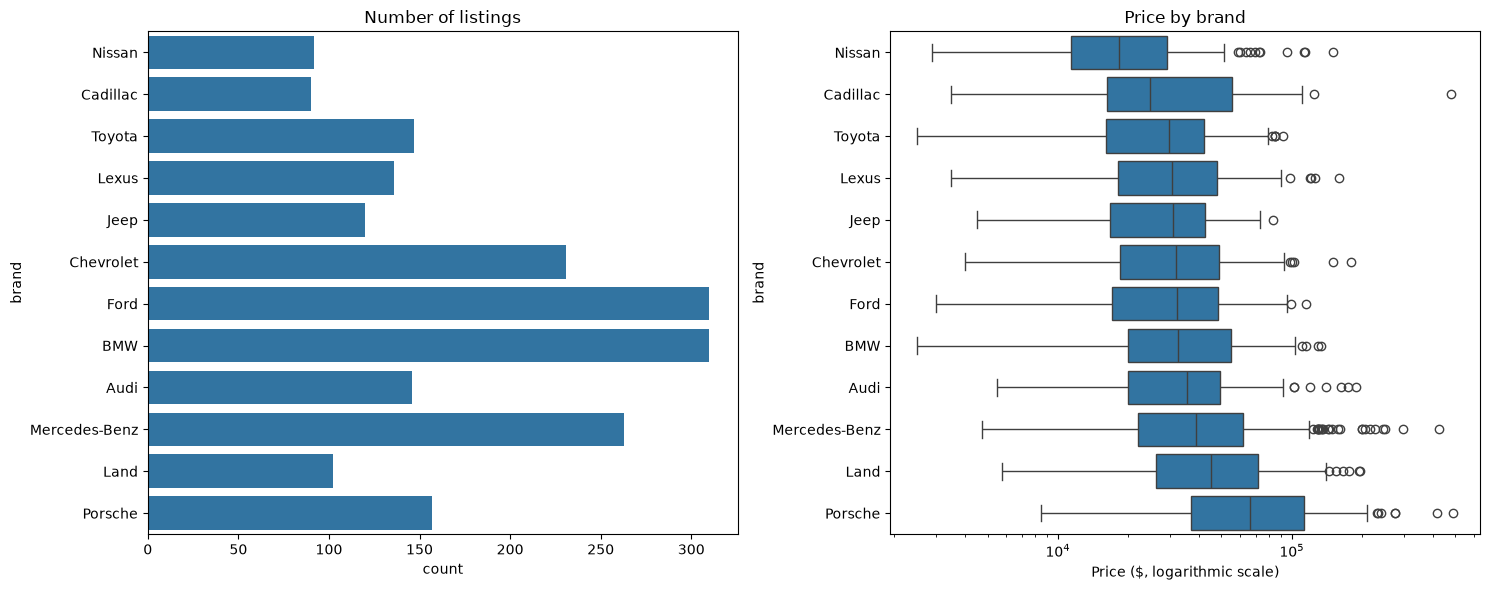

In [20]:
top_brands = train_df["brand"].value_counts().head(12).index

brand_data = train_df.loc[train_df["brand"].isin(top_brands)]

brand_order = (
    brand_data.groupby("brand")["price"]
    .median()
    .sort_values()
    .index
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.countplot(
    data=brand_data,
    y="brand",
    order=brand_order,
    ax=axes[0],
)
axes[0].set_title("Number of listings")

sns.boxplot(
    data=brand_data,
    y="brand",
    x="price",
    order=brand_order,
    ax=axes[1],
)
axes[1].set_xscale("log")
axes[1].set_title("Price by brand")
axes[1].set_xlabel("Price ($, logarithmic scale)")

plt.tight_layout()
plt.show()

,count,median
category,,
not supported,2,14000.0
E85 Flex Fuel,117,18500.0
Gasoline,2643,29950.0
Plug-In Hybrid,30,44945.0
Unknown,162,44995.0
Hybrid,158,47299.0
Diesel,95,49883.0


,count,median
category,,
At least 1 accident or damage reported,784,20925.0
Unknown,91,35645.0
None reported,2332,35750.0


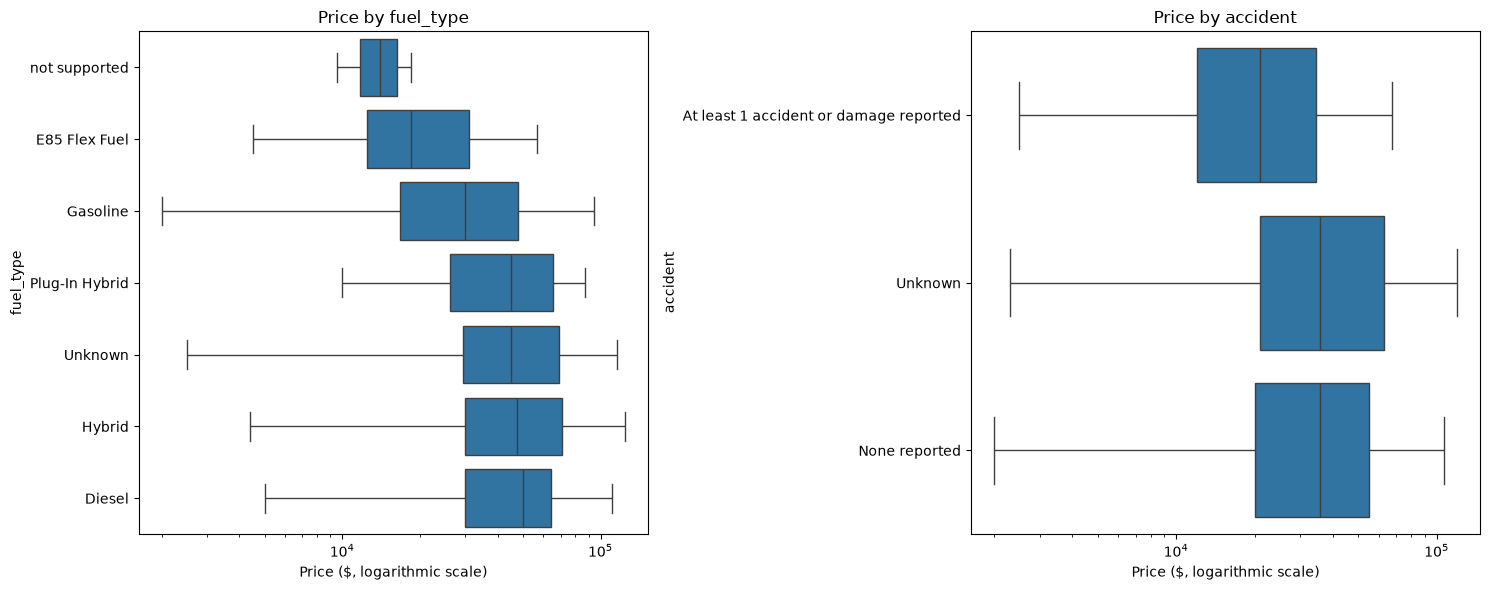

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, column in zip(axes, ["fuel_type", "accident"]):
    plot_data = train_df.assign(
        category=train_df[column].fillna("Unknown")
    )

    summary = (
        plot_data.groupby("category")["price"]
        .agg(["count", "median"])
        .sort_values("median")
    )
    display(summary)

    sns.boxplot(
        data=plot_data,
        y="category",
        x="price",
        order=summary.index,
        showfliers=False,
        ax=ax,
    )
    ax.set_xscale("log")
    ax.set_ylabel(column)
    ax.set_xlabel("Price ($, logarithmic scale)")
    ax.set_title(f"Price by {column}")

plt.tight_layout()
plt.show()

In [22]:
missing_summary = pd.DataFrame({
    "missing_count": train_df.isna().sum(),
    "missing_percent": train_df.isna().mean() * 100,
}).sort_values("missing_count", ascending=False)

display(missing_summary.loc[missing_summary["missing_count"] > 0])

for column in ["fuel_type", "accident", "clean_title"]:
    summary = (
        train_df.assign(is_missing=train_df[column].isna())
        .groupby("is_missing")
        .agg(
            count=("price", "size"),
            median_price=("price", "median"),
            median_year=("model_year", "median"),
            median_mileage=("milage", "median"),
        )
    )
    print(f"\n{column}")
    display(summary)

,missing_count,missing_percent
clean_title,470,14.655441
fuel_type,162,5.051450
accident,91,2.837543
engine,35,1.091363
transmission,4,0.124727



fuel_type


,count,median_price,median_year,median_mileage
is_missing,,,,
False,3045,30000.0,2017.0,55000.0
True,162,44995.0,2020.0,24054.5



accident


,count,median_price,median_year,median_mileage
is_missing,,,,
False,3116,31000.0,2017.0,53729.5
True,91,35645.0,2018.0,38000.0



clean_title


,count,median_price,median_year,median_mileage
is_missing,,,,
False,2737,29000.0,2016.0,60345.0
True,470,42900.0,2020.0,24509.5


In [23]:
categorical_columns = ["brand", "model", "fuel_type", "engine", "transmission", "ext_col", "int_col"]

rows = []

for column in categorical_columns:
    counts = train_df[column].value_counts()
    rows.append({
        "feature": column,
        "unique_values": len(counts),
        "categories_seen_once": int((counts == 1).sum()),
        "rows_in_categories_with_under_5_examples": int(
            counts.loc[counts < 5].sum()
        ),
    })

display(pd.DataFrame(rows).set_index("feature"))

,unique_values,categories_seen_once,rows_in_categories_with_under_5_examples
feature,,,
brand,56,7,17
model,1634,968,2345
fuel_type,6,0,2
engine,1037,489,1484
transmission,59,21,52
ext_col,271,186,331
int_col,135,91,158


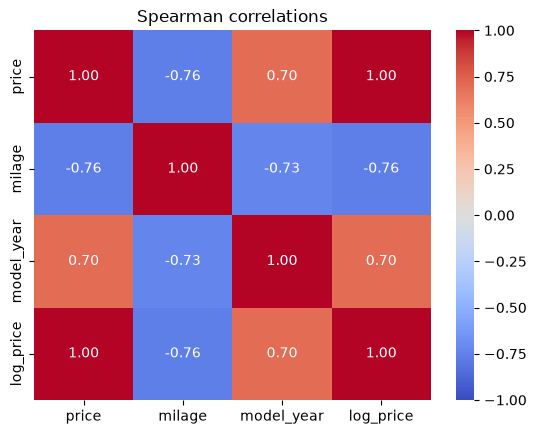

In [24]:
numeric_view = train_df[["price", "milage", "model_year"]].copy()
numeric_view["log_price"] = np.log1p(numeric_view["price"])

sns.heatmap(
    numeric_view.corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)
plt.title("Spearman correlations")
plt.show()

### Выводы

- Распределение цены скошено вправо: медиана 31 300, среднее 43 126, максимум 749 950
- Медианная цена снижается с ростом пробега и в целом увеличивается для более новых автомобилей
- У автомобилей с зарегистрированными ДТП медианная цена ниже: 20 925 против 35 750 без зарегистрированных ДТП. Это сравнение не учитывает остальные характеристики
- Пропуски связаны с различиями в возрасте, пробеге и цене автомобилей, поэтому удалять такие строки автоматически не стоит
- В model и engine много редких категорий. При кодировании нужно учитывать появление неизвестных значений
- Среди самых дорогих машин есть люксовые модели, поэтому высокая цена сама по себе не является основанием для удаления
- Наблюдения описывают связи в данных, гипотезы о качестве моделей проверим отдельными экспериментами

## Preprocessing
Конечно будем использовать кросс-валидацию, поэтому тут данные бьем на 5 фолдов. Численные признаки заменяем на медиану и опционально скейлим внутри фолда. Категориальные признаки либо просто разворачиваем в OneHot представление с категорией Unknown для nan, либо также OneHot представдение, но редкие представители (у нас это менее 5) идут в одну общую категорию. Далее будем сравнивать что и как лучше.

In [25]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.base import clone

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import KFold, GridSearchCV

X_train = train_df.drop(columns="price").copy()
y_train = train_df["price"].copy()
cv = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train))

In [26]:
def make_preprocessor(numeric, categorical, encoding="onehot", scale=True):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]

    if scale:
        numeric_steps.append(("scaler", StandardScaler()))

    transformers = [("numeric", Pipeline(numeric_steps), numeric)]

    for column in categorical:
        mode = (encoding.get(column, "onehot") if isinstance(encoding, dict) else encoding)
        options = {"handle_unknown": "ignore"}
        if mode == "rare":
            options = {
                "handle_unknown": "infrequent_if_exist",
                "min_frequency": 5,
            }

        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(
                strategy="constant",
                fill_value="Unknown",
            )),
            ("encoder", OneHotEncoder(**options)),
        ])

        transformers.append(
            (f"categorical_{column}", categorical_pipeline, [column])
        )

    return ColumnTransformer(transformers, remainder="drop")

## Эксперемнтальный сетап
Будем сравнивать линейную регрессию, Ridge и дерево решений. Медианный прогноз используется как baseline. Используем одинаковые 5 фолдов кросс-валидации для всех экспериментов. Заполнение пропусков, масштабирование и кодирование категорий выполняются внутри pipeline отдельно на обучающей части каждого фолда. Основная метрику берем MAE, так как она сразу показывает как сильно мы ошибаемся в долларах, одинаково оценивает ошибку в обе стороны, также медианную AE. Дополнительно измеряем RMSE, чтобы учитывать крупные ошибки, и $R^2$. Гиперпараметры выбираются по минимальной MAE. Тестовая выборка не используется до выбора итоговой модели. Для заданного набора признаков функция создаёт pipeline каждой модели, подбирает гиперпараметры и сохраняет результаты кросс-валидации.

In [27]:
model_specs = {
    "Median": (DummyRegressor(strategy="median"), {}),
    "Linear": (LinearRegression(), {}),
    "Ridge": (Ridge(solver="lsqr"), {"alpha": [0.1, 1, 10, 100]}),
    "Tree": (DecisionTreeRegressor(random_state=RANDOM_STATE), {"max_depth": [1, 5, 10, 15, 25, None], "min_samples_leaf": [1, 5, 10, 20]}),
}

In [28]:
scoring = {
    "MAE": "neg_mean_absolute_error",
    "MedAE": "neg_median_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

results = []
searches = {}


def run_experiment(name, numeric, categorical, encoding="onehot", log_target=False, models=("Linear", "Ridge", "Tree")):
    for model_name in models:
        estimator, grid = model_specs[model_name]

        pipeline = Pipeline([
            ("preprocessing", make_preprocessor(
                numeric=numeric,
                categorical=categorical,
                encoding=encoding,
                scale=model_name in ("Linear", "Ridge"),
            )),
            ("model", clone(estimator)),
        ])

        params = {
            f"model__{key}": values
            for key, values in grid.items()
        }

        if log_target:
            pipeline = TransformedTargetRegressor(
                regressor=pipeline,
                func=np.log1p,
                inverse_func=np.expm1,
            )
            params = {
                f"regressor__{key}": values
                for key, values in params.items()
            }

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=params,
            scoring=scoring,
            refit="MAE",
            cv=cv,
            return_train_score=True,
            n_jobs=-1,
            error_score="raise",
        )
        search.fit(X_train, y_train)

        best = search.best_index_
        scores = search.cv_results_
        row = {
            "experiment": name,
            "model": model_name,
            "train_MAE": -scores["mean_train_MAE"][best],
            "validation_MAE": -scores["mean_test_MAE"][best],
            "validation_MedAE": -scores["mean_test_MedAE"][best],
            "MAE_std": scores["std_test_MAE"][best],
            "validation_RMSE": -scores["mean_test_RMSE"][best],
            "validation_R2": scores["mean_test_R2"][best],
            "best_params": search.best_params_,
        }
        results[:] = [
            item for item in results
            if (item["experiment"], item["model"])
            != (name, model_name)
        ]
        results.append(row)

        searches[(name, model_name)] = search

    return (
        pd.DataFrame(results)
        .loc[lambda table: table["experiment"] == name]
        .sort_values("validation_MAE")
        .reset_index(drop=True)
    )

## Эксперименты и проверка гипотез
Начнем со сравнения моделей которые используют только численные признаки

In [29]:
numeric_features = ["model_year", "milage"]

display(run_experiment(
    name="numeric",
    numeric=numeric_features,
    categorical=[],
    models=("Median", "Linear", "Ridge", "Tree"),
))

,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,numeric,Tree,18958.637104,20010.285230,9830.380747,2171.785005,41905.459464,0.302659,"{'model__max_depth': 5, 'model__min_samples_le..."
1,numeric,Ridge,22701.505318,22704.760503,15622.796182,1939.426826,44756.425013,0.211570,{'model__alpha': 100}
2,numeric,Linear,22838.730165,22840.520480,15698.603748,1943.081438,44760.997608,0.211115,{}
3,numeric,Median,25577.563648,25641.249667,15739.200000,2553.012018,51620.495318,-0.054089,{}


Добавим бренд и модель, сравним как лучше представлять (обычный OneHot или с объединением редких)

In [30]:
identity_features = ["brand", "model"]

for encoding in ["onehot", "rare"]:
    display(run_experiment(
        name=f"brand_model_{encoding}",
        numeric=numeric_features,
        categorical=identity_features,
        encoding=encoding,
    ))

,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,brand_model_onehot,Ridge,4370.126332,11692.205748,5687.856398,1202.921902,25821.508609,0.725634,{'model__alpha': 0.1}
1,brand_model_onehot,Linear,3746.791027,11714.967642,5614.820997,1219.786621,26052.938644,0.719249,{}
2,brand_model_onehot,Tree,4828.474279,14317.885196,7388.522884,1024.525634,29396.262138,0.634933,"{'model__max_depth': 25, 'model__min_samples_l..."


,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,brand_model_rare,Tree,11052.676714,16256.039522,8516.572646,2450.401199,35078.214575,0.517151,"{'model__max_depth': 10, 'model__min_samples_l..."
1,brand_model_rare,Linear,15425.148845,16616.348254,9853.209725,1721.821216,34352.760802,0.527321,{}
2,brand_model_rare,Ridge,15431.866185,16618.234125,9863.340233,1726.111834,34326.718048,0.528547,{'model__alpha': 0.1}


Простой OneHot оказался лучше, действительно, редкая марка и модель часто может многое сказать о цене и отстутсвие возможности их различать нам помешает. Теперь добавим остальные признаки, кроме цветов

In [31]:
vehicle_categories = ["brand", "model", "fuel_type", "transmission", "accident", "clean_title"]

vehicle_configs = {
    "vehicle_onehot": {
        "categorical": vehicle_categories,
        "encoding": {},
    },
    "vehicle_rare_transmission": {
        "categorical": vehicle_categories,
        "encoding": {"transmission": "rare"},
    },
    "raw_engine_onehot": {
        "categorical": vehicle_categories + ["engine"],
        "encoding": {},
    },
    "raw_engine_rare_transmission": {
        "categorical": vehicle_categories + ["engine"],
        "encoding": {"transmission": "rare"},
    },
    "raw_engine_rare_engine": {
        "categorical": vehicle_categories + ["engine"],
        "encoding": {"engine": "rare"},
    },
    "raw_engine_rare_both": {
        "categorical": vehicle_categories + ["engine"],
        "encoding": {
            "engine": "rare",
            "transmission": "rare",
        },
    },
}

for name, config in vehicle_configs.items():
    display(run_experiment(
        name=name,
        numeric=numeric_features,
        categorical=config["categorical"],
        encoding=config["encoding"],
    ))

,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,vehicle_onehot,Ridge,4531.993202,12470.658895,6628.040878,968.290503,26245.088056,0.713252,{'model__alpha': 0.1}
1,vehicle_onehot,Linear,3988.395750,12994.186533,6867.568481,1030.085850,27024.155312,0.693897,{}
2,vehicle_onehot,Tree,4106.242354,14626.635297,7461.479833,1076.735420,30370.859752,0.611800,"{'model__max_depth': 25, 'model__min_samples_l..."


,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,vehicle_rare_transmission,Ridge,4659.252718,12394.470197,6709.180922,1124.911361,25514.826696,0.731425,{'model__alpha': 0.1}
1,vehicle_rare_transmission,Linear,4110.792703,12877.173744,6968.576243,1152.915506,26226.735753,0.715271,{}
2,vehicle_rare_transmission,Tree,8417.076715,14771.588974,8069.272542,1138.162647,30061.427342,0.623346,"{'model__max_depth': 15, 'model__min_samples_l..."


,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,raw_engine_onehot,Ridge,5779.042683,12191.718623,6665.942645,777.940909,26539.000510,0.720263,{'model__alpha': 1}
1,raw_engine_onehot,Linear,1878.404313,13939.240511,6671.269163,1527.492754,31316.898295,0.605736,{}
2,raw_engine_onehot,Tree,4066.506450,14636.538884,7489.819950,1579.908847,31370.282439,0.590052,"{'model__max_depth': 25, 'model__min_samples_l..."


,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,raw_engine_rare_transmission,Ridge,5948.283295,12309.023029,6824.344568,863.362704,26137.599588,0.728320,{'model__alpha': 1}
1,raw_engine_rare_transmission,Tree,1.286291,15234.194068,7376.500000,1143.701714,33994.554525,0.482079,"{'model__max_depth': None, 'model__min_samples..."
2,raw_engine_rare_transmission,Linear,1898.922963,15467.124487,7165.526705,1898.240086,32564.925625,0.577085,{}


,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,raw_engine_rare_engine,Ridge,4183.355905,12681.707333,6663.974282,802.428010,26592.472821,0.711128,{'model__alpha': 0.1}
1,raw_engine_rare_engine,Linear,3518.676503,13990.573019,7030.657412,896.797971,30013.761439,0.638206,{}
2,raw_engine_rare_engine,Tree,3937.852294,14751.834847,7424.150565,1356.395189,32503.788627,0.553398,"{'model__max_depth': 25, 'model__min_samples_l..."


,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,raw_engine_rare_both,Ridge,4304.294245,12547.307823,6680.811759,973.405276,25864.441004,0.729552,{'model__alpha': 0.1}
1,raw_engine_rare_both,Linear,3655.408492,13558.970558,7083.743283,1123.290692,28222.984204,0.682677,{}
2,raw_engine_rare_both,Tree,3925.407476,14994.065391,7323.030572,1526.171945,34266.834192,0.515212,"{'model__max_depth': 25, 'model__min_samples_l..."


In [32]:
summary = pd.DataFrame(results)

display(
    summary.pivot(
        index="experiment",
        columns="model",
        values=["validation_MAE", "validation_MedAE"],
    ).round(0)
)

validation_MAE                             \
model                                Linear   Median    Ridge     Tree   
experiment                                                               
brand_model_onehot                  11715.0      NaN  11692.0  14318.0   
brand_model_rare                    16616.0      NaN  16618.0  16256.0   
numeric                             22841.0  25641.0  22705.0  20010.0   
raw_engine_onehot                   13939.0      NaN  12192.0  14637.0   
raw_engine_rare_both                13559.0      NaN  12547.0  14994.0   
raw_engine_rare_engine              13991.0      NaN  12682.0  14752.0   
raw_engine_rare_transmission        15467.0      NaN  12309.0  15234.0   
vehicle_onehot                      12994.0      NaN  12471.0  14627.0   
vehicle_rare_transmission           12877.0      NaN  12394.0  14772.0   

                             validation_MedAE                            
model                                  Linear   Median    Ridge    Tree  
experiment                                                               
brand_model_onehot                     5615.0      NaN   5688.0  7389.0  
brand_model_rare                       9853.0      NaN   9863.0  8517.0  
numeric                               15699.0  15739.0  15623.0  9830.0  
raw_engine_onehot                      6671.0      NaN   6666.0  7490.0  
raw_engine_rare_both                   7084.0      NaN   6681.0  7323.0  
raw_engine_rare_engine                 7031.0      NaN   6664.0  7424.0  
raw_engine_rare_transmission           7166.0      NaN   6824.0  7376.0  
vehicle_onehot                         6868.0      NaN   6628.0  7461.0  
vehicle_rare_transmission              6969.0      NaN   6709.0  8069.0

Лучше всех себя показала модель с брендом, моделью и цисленными признаками с обычным onehot. Пояснение: медиана во всех сроках будет одинаковая, поэтому она не перезапускалась и NaN там это не проблема с данными, а отображение в таблице. Теперь для каждого варианта модели выберем лучшие гиперпараметры

In [33]:
candidate_configs = {
    "numeric": {
        "categorical": [],
        "encoding": {},
    },
    "brand_model_onehot": {
        "categorical": identity_features,
        "encoding": {},
    },
    "brand_model_rare": {
        "categorical": identity_features,
        "encoding": {
            "brand": "rare",
            "model": "rare",
        },
    },
    **vehicle_configs,
}

candidate_results = pd.DataFrame(results)

candidate_results = candidate_results.loc[
    candidate_results["experiment"].isin(candidate_configs)
    & candidate_results["model"].isin(["Linear", "Ridge", "Tree"])
]

best_indices = candidate_results.groupby("model")["validation_MAE"].idxmin()

selected = (
    candidate_results.loc[best_indices]
    .set_index("model")["experiment"]
    .to_dict()
)

display(
    candidate_results.loc[
        best_indices,
        ["model", "experiment", "validation_MAE", "validation_MedAE"],
    ]
)

,model,experiment,validation_MAE,validation_MedAE
4,Linear,brand_model_onehot,11714.967642,5614.820997
5,Ridge,brand_model_onehot,11692.205748,5687.856398
6,Tree,brand_model_onehot,14317.885196,7388.522884


Теперь добавим признаки цветов

In [34]:
for model_name, config_name in selected.items():
    config = candidate_configs[config_name]

    display(run_experiment(
        name="selected_plus_colors",
        numeric=numeric_features,
        categorical=config["categorical"] + ["ext_col", "int_col"],
        encoding=config["encoding"],
        models=(model_name,),
    ))

,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,selected_plus_colors,Linear,2900.497963,12192.883214,6662.832192,1386.784599,25005.558449,0.750389,{}


,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,selected_plus_colors,Ridge,3599.419099,12069.677102,6547.815095,1294.427071,24979.646356,0.751035,{'model__alpha': 0.1}
1,selected_plus_colors,Linear,2900.497963,12192.883214,6662.832192,1386.784599,25005.558449,0.750389,{}


,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,selected_plus_colors,Ridge,3599.419099,12069.677102,6547.815095,1294.427071,24979.646356,0.751035,{'model__alpha': 0.1}
1,selected_plus_colors,Linear,2900.497963,12192.883214,6662.832192,1386.784599,25005.558449,0.750389,{}
2,selected_plus_colors,Tree,4466.965966,14753.088891,7554.654430,1349.581506,29196.683724,0.659107,"{'model__max_depth': 25, 'model__min_samples_l..."


Теперь достанем параметры мотора

In [35]:
engine = X_train["engine"].astype("string")

patterns = {
    "horsepower": r"(?i)(\d+(?:\.\d+)?)\s*HP\b",
    "displacement": r"(?i)(\d+(?:\.\d+)?)\s*(?:L\b|Liter\b)",
    "cylinders": r"(?i)(?:V|I|H|W)\s*(\d{1,2})\b",
}

for feature, pattern in patterns.items():
    X_train[feature] = pd.to_numeric(
        engine.str.extract(pattern, expand=False),
        errors="coerce",
    ).astype(float)

alternative_cylinders = pd.to_numeric(
    engine.str.extract(
        r"(?i)(\d{1,2})\s*Cylinder",
        expand=False,
    ),
    errors="coerce",
).astype(float)

X_train["cylinders"] = X_train["cylinders"].fillna(alternative_cylinders)

engine_features = ["horsepower", "displacement", "cylinders"]

display(
    X_train[engine_features]
    .notna()
    .mean()
    .rename("extraction_coverage")
)

display(
    X_train[["engine"] + engine_features]
    .sample(15, random_state=RANDOM_STATE)
)

horsepower      0.802619
displacement    0.949486
cylinders       0.899595
Name: extraction_coverage, dtype: float64

,engine,horsepower,displacement,cylinders
2436,355.0HP 5.3L 8 Cylinder Engine Gasoline Fuel,355.0,5.3,8.0
779,381.0HP 5.7L 8 Cylinder Engine Flex Fuel Capab...,381.0,5.7,8.0
2324,3.6 Liter,NaN,3.6,NaN
3420,550.0HP 5.0L 8 Cylinder Engine Flex Fuel Capab...,550.0,5.0,8.0
3921,310.0HP 5.7L 8 Cylinder Engine Gasoline Fuel,310.0,5.7,8.0
272,402.0HP 4.7L 8 Cylinder Engine Gasoline Fuel,402.0,4.7,8.0
663,375.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,375.0,3.5,6.0
2497,485.0HP 6.4L 8 Cylinder Engine Gasoline Fuel,485.0,6.4,8.0
1494,285.0HP 3.6L V6 Cylinder Engine Gasoline Fuel,285.0,3.6,6.0
587,563.0HP 6.6L 12 Cylinder Engine Gasoline Fuel,563.0,6.6,12.0


In [36]:
for model_name, config_name in selected.items():
    config = candidate_configs[config_name]

    display(run_experiment(
        name="selected_plus_engine_features",
        numeric=numeric_features + engine_features,
        categorical=config["categorical"],
        encoding=config["encoding"],
        models=(model_name,),
    ))

,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,selected_plus_engine_features,Linear,3852.835618,12412.097757,6160.62989,1021.492373,26519.166168,0.7067,{}


,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,selected_plus_engine_features,Ridge,4507.738414,11657.853354,6013.995136,1043.370824,25490.385305,0.731313,{'model__alpha': 0.1}
1,selected_plus_engine_features,Linear,3852.835618,12412.097757,6160.629890,1021.492373,26519.166168,0.706700,{}


,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,selected_plus_engine_features,Ridge,4507.738414,11657.853354,6013.995136,1043.370824,25490.385305,0.731313,{'model__alpha': 0.1}
1,selected_plus_engine_features,Linear,3852.835618,12412.097757,6160.629890,1021.492373,26519.166168,0.706700,{}
2,selected_plus_engine_features,Tree,1.286291,12783.162267,5716.400000,1763.101314,30331.535248,0.604156,"{'model__max_depth': None, 'model__min_samples..."


Теперь будем предсказывать логарифм вместо непосредственно самой цены

In [37]:
for model_name, config_name in selected.items():
    config = candidate_configs[config_name]

    display(run_experiment(
        name="selected_plus_engine_features_log",
        numeric=numeric_features + engine_features,
        categorical=config["categorical"],
        encoding=config["encoding"],
        log_target=True,
        models=(model_name,),
    ))

,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,selected_plus_engine_features_log,Linear,3001.160873,10056.707802,4052.025313,1737.354728,32873.808226,0.367274,{}


,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,selected_plus_engine_features_log,Ridge,3614.395163,9248.347596,3899.880628,1426.287924,28592.582068,0.581610,{'regressor__model__alpha': 0.1}
1,selected_plus_engine_features_log,Linear,3001.160873,10056.707802,4052.025313,1737.354728,32873.808226,0.367274,{}


,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,selected_plus_engine_features_log,Ridge,3614.395163,9248.347596,3899.880628,1426.287924,28592.582068,0.581610,{'regressor__model__alpha': 0.1}
1,selected_plus_engine_features_log,Linear,3001.160873,10056.707802,4052.025313,1737.354728,32873.808226,0.367274,{}
2,selected_plus_engine_features_log,Tree,1.286291,12294.327441,5393.400000,1868.539986,31096.166987,0.610915,"{'regressor__model__max_depth': None, 'regress..."


Стало немного лучше, теперь посмотрим на все наши варианты добавлений

In [38]:
summary = pd.DataFrame(results)


def compare_pair(label, before, after, model):
    table = (summary.loc[summary["model"] == model].set_index("experiment"))
    old_mae = table.loc[before, "validation_MAE"]
    new_mae = table.loc[after, "validation_MAE"]

    return {
        "comparison": label,
        "model": model,
        "before_MAE": old_mae,
        "after_MAE": new_mae,
        "improvement_pct": 100 * (old_mae - new_mae) / old_mae,
        "before_MedAE": table.loc[before, "validation_MedAE"],
        "after_MedAE": table.loc[after, "validation_MedAE"],
    }


paired_results = []

for model in ["Linear", "Ridge", "Tree"]:
    pairs = [
        ("Add brand/model", "numeric", "brand_model_onehot"),
        (
            "Group rare brand/model",
            "brand_model_onehot",
            "brand_model_rare",
        ),
        (
            "Add vehicle characteristics",
            "brand_model_onehot",
            "vehicle_onehot",
        ),
        (
            "Group rare transmission",
            "vehicle_onehot",
            "vehicle_rare_transmission",
        ),
        ("Add raw engine", "vehicle_onehot", "raw_engine_onehot"),
        (
            "Group rare engine",
            "raw_engine_onehot",
            "raw_engine_rare_engine",
        ),
        ("Add colors", selected[model], "selected_plus_colors"),
        (
            "Add extracted engine features",
            selected[model],
            "selected_plus_engine_features",
        ),
        (
            "Log target",
            "selected_plus_engine_features",
            "selected_plus_engine_features_log",
        ),
    ]

    for label, before, after in pairs:
        paired_results.append(
            compare_pair(label, before, after, model)
        )

display(pd.DataFrame(paired_results).round(2))

,comparison,model,before_MAE,after_MAE,improvement_pct,before_MedAE,after_MedAE
0,Add brand/model,Linear,22840.52,11714.97,48.71,15698.60,5614.82
1,Group rare brand/model,Linear,11714.97,16616.35,-41.84,5614.82,9853.21
2,Add vehicle characteristics,Linear,11714.97,12994.19,-10.92,5614.82,6867.57
3,Group rare transmission,Linear,12994.19,12877.17,0.90,6867.57,6968.58
4,Add raw engine,Linear,12994.19,13939.24,-7.27,6867.57,6671.27
5,Group rare engine,Linear,13939.24,13990.57,-0.37,6671.27,7030.66
6,Add colors,Linear,11714.97,12192.88,-4.08,5614.82,6662.83
7,Add extracted engine features,Linear,11714.97,12412.10,-5.95,5614.82,6160.63
8,Log target,Linear,12412.10,10056.71,18.98,6160.63,4052.03
9,Add brand/model,Ridge,22704.76,11692.21,48.50,15622.80,5687.86


Видим, что очень хорошо помогает бренд и модель (но при этом нельзя группировать редкие в одно), также хорошо помогает предсказывание логарифма, но только линейной и Ridge регрессии (понятно, так как для дерева это неважно). Остальное не меняяет или делает хуже

## Проверка гипотез

- Если убрать признаки цвета интерьера и экстерьера, валидационная MAE изменится в пределах 2%, так как эти фичи не так сильно влияют на стоимость

,Without colors,With colors,Removal change (%),Within 2%
model,,,,
Linear,11714.97,12192.88,-3.92,False
Ridge,11692.21,12069.68,-3.13,False
Tree,14317.89,14753.09,-2.95,False


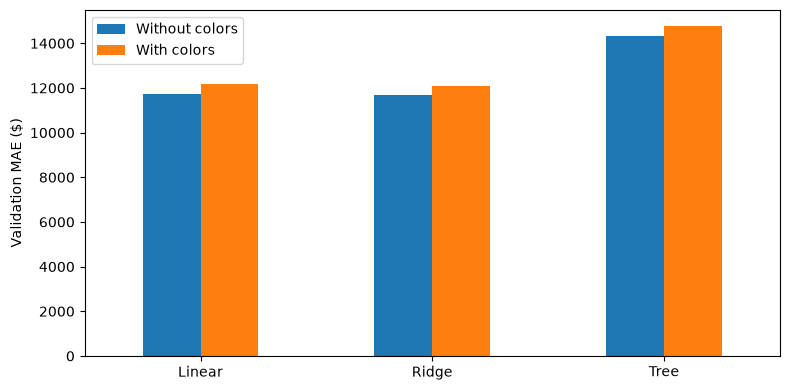

In [39]:
summary = pd.DataFrame(results)
rows = []

for model, baseline in selected.items():
    table = summary.loc[summary["model"] == model].set_index("experiment")
    without = table.loc[baseline, "validation_MAE"]
    with_colors = table.loc["selected_plus_colors", "validation_MAE"]
    change = 100 * (without - with_colors) / with_colors

    rows.append({
        "model": model,
        "Without colors": without,
        "With colors": with_colors,
        "Removal change (%)": change,
        "Within 2%": abs(change) <= 2,
    })

comparison = pd.DataFrame(rows).set_index("model")
display(comparison.round(2))

comparison[["Without colors", "With colors"]].plot.bar(figsize=(8, 4), rot=0)
plt.ylabel("Validation MAE ($)")
plt.xlabel("")
plt.tight_layout()
plt.show()

Гипотеза не подтвердилась в смысле процентов, но по смыслу получилось примерно также

- Дерево без ограничений на глубину заоверфиттится больше чем средней глубины, без ограничений MAE будет меньше на трейне, но больше на тесте

,depth,train_MAE,validation_MAE,validation_MedAE
0,2,20653.44,21334.23,12349.99
1,3,18453.12,18832.30,10889.92
2,5,15802.78,17207.36,9558.32
3,10,11457.56,15438.94,8503.68
4,15,8811.10,14966.60,8157.71
5,25,4828.47,14317.89,7388.52
6,50,833.54,14629.32,7280.57
7,Unlimited,1.29,14958.18,7350.90


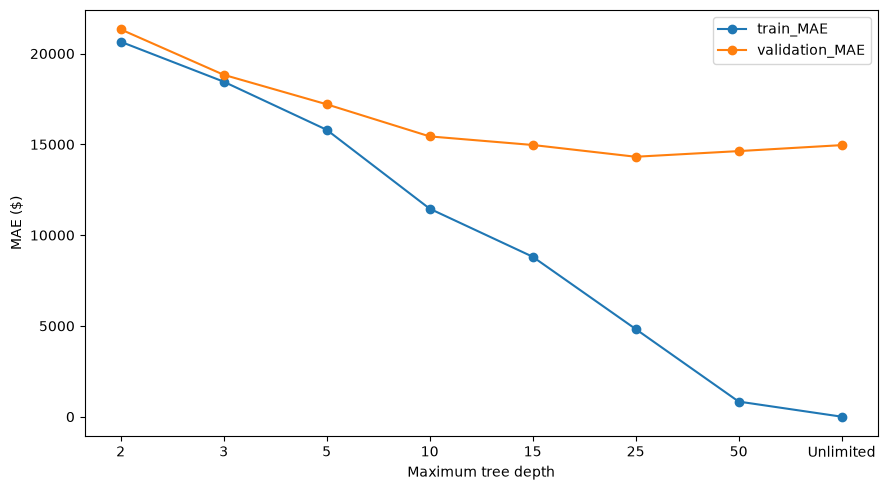

In [40]:
from sklearn.model_selection import cross_validate

tree_config = candidate_configs[selected["Tree"]]

depths = [2, 3, 5, 10, 15, 25, 50, None]
depth_rows = []

for depth in depths:
    pipeline = Pipeline([
        ("preprocessing", make_preprocessor(
            numeric=numeric_features,
            categorical=tree_config["categorical"],
            encoding=tree_config["encoding"],
            scale=False,
        )),
        ("model", DecisionTreeRegressor(
            max_depth=depth,
            min_samples_leaf=1,
            random_state=RANDOM_STATE,
        )),
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1,
    )

    depth_rows.append({
        "depth": str(depth) if depth is not None else "Unlimited",
        "train_MAE": -scores["train_MAE"].mean(),
        "validation_MAE": -scores["test_MAE"].mean(),
        "validation_MedAE": -scores["test_MedAE"].mean(),
    })

depth_results = pd.DataFrame(depth_rows)
display(depth_results.round(2))

depth_results.set_index("depth")[
    ["train_MAE", "validation_MAE"]
].plot(marker="o", figsize=(9, 5))

plt.xlabel("Maximum tree depth")
plt.ylabel("MAE ($)")
plt.tight_layout()
plt.show()

Гипотеза подтвердилась: с увеличением глубины MAE на трейне падает из-за оверфиттинга, а валидационное выходит на плато

- Дерево с подобранной глубиной достигнет валидационного MAE ниже чем линейная регрессия, так как цена опирается на нелинейные соотношения

model,Linear,Tree,Tree better
experiment,,,
brand_model_onehot,11714.97,14317.89,False
brand_model_rare,16616.35,16256.04,True
numeric,22840.52,20010.29,True
raw_engine_onehot,13939.24,14636.54,False
raw_engine_rare_both,13558.97,14994.07,False
raw_engine_rare_engine,13990.57,14751.83,False
raw_engine_rare_transmission,15467.12,15234.19,True
vehicle_onehot,12994.19,14626.64,False
vehicle_rare_transmission,12877.17,14771.59,False


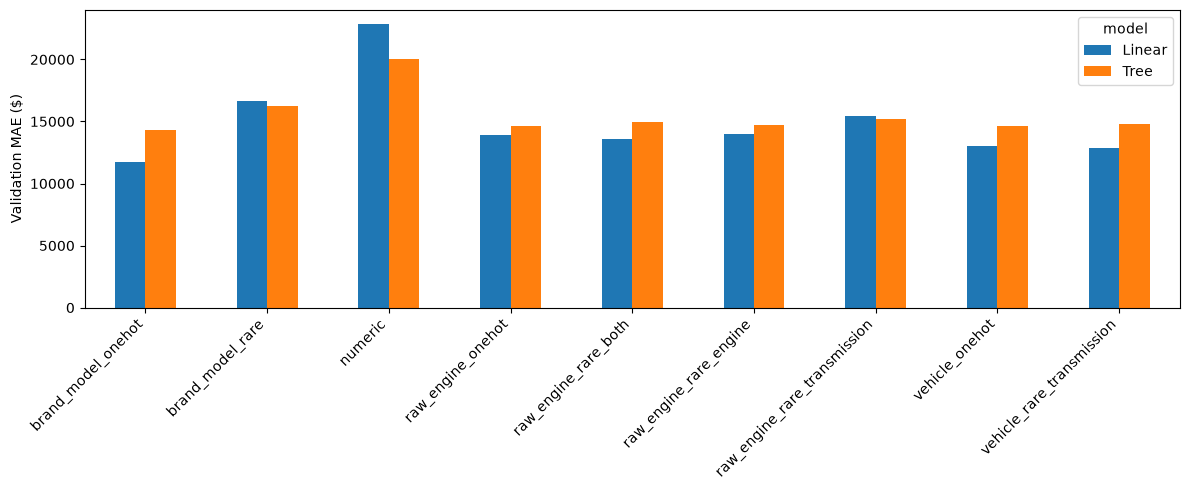

In [41]:
summary = pd.DataFrame(results)

comparison = summary.loc[
    summary["experiment"].isin(candidate_configs)
    & summary["model"].isin(["Linear", "Tree"])
].pivot(
    index="experiment",
    columns="model",
    values="validation_MAE",
).dropna()

comparison["Tree better"] = comparison["Tree"] < comparison["Linear"]

display(comparison.round(2))

comparison[["Linear", "Tree"]].plot.bar(figsize=(12, 5))

plt.ylabel("Validation MAE ($)")
plt.xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Гипотеза не подтвердилась для выбранного представления признаков. На одних численных признаках дерево оказалось лучше. Следовательно, преимущество модели зависит от представления признаков, нелинейность зависимостей сама по себе не гарантирует превосходства дерева.

- Предсказывать `log(1 + p)` где `p` это цена даст валидацонное MAE ниже чем просто предсказание цены, так как очень дорогие машины не будут так сильно влиять на модель

,Direct price,Log target,Improvement (%)
model,,,
Linear,12412.10,10056.71,18.98
Ridge,11657.85,9248.35,20.67
Tree,12783.16,12294.33,3.82


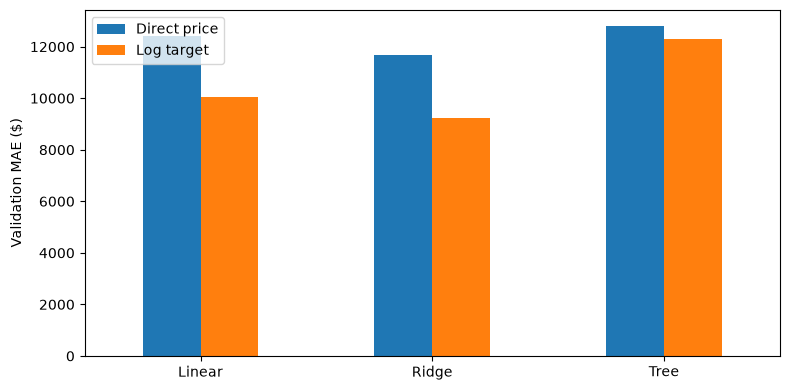

In [42]:
rows = []

for model in selected:
    table = summary.loc[summary["model"] == model].set_index("experiment")
    direct = table.loc["selected_plus_engine_features", "validation_MAE"]
    logged = table.loc["selected_plus_engine_features_log", "validation_MAE"]
    rows.append({
        "model": model,
        "Direct price": direct,
        "Log target": logged,
        "Improvement (%)": 100 * (direct - logged) / direct,
    })

comparison = pd.DataFrame(rows).set_index("model")
display(comparison.round(2))

comparison[["Direct price", "Log target"]].plot.bar(figsize=(8, 4), rot=0)
plt.ylabel("Validation MAE ($)")
plt.xlabel("")
plt.tight_layout()
plt.show()

Гипотеза поддтвердилась, предсказывать логарифм действительно лучше

- Если достать из описания мотора доп параметры (например, лошадиные силы, количество цилиндров и тд), то валидационное MAE уменьшится

,Before extraction,With extracted features,Improvement (%)
model,,,
Linear,11714.97,12412.10,-5.95
Ridge,11692.21,11657.85,0.29
Tree,14317.89,12783.16,10.72


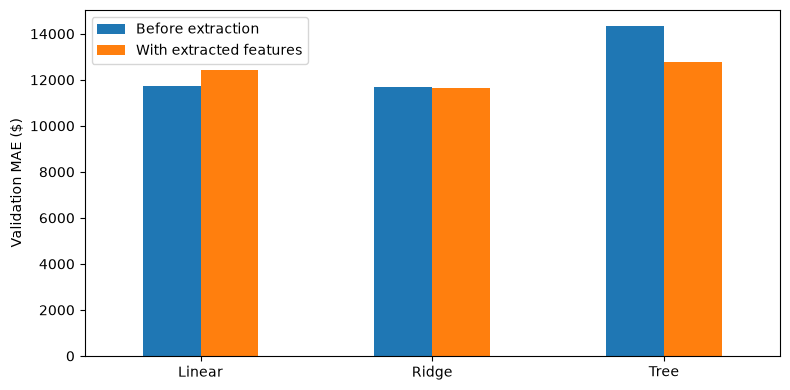

In [43]:
rows = []

for model, baseline in selected.items():
    table = summary.loc[summary["model"] == model].set_index("experiment")
    before = table.loc[baseline, "validation_MAE"]
    after = table.loc["selected_plus_engine_features", "validation_MAE"]
    rows.append({
        "model": model,
        "Before extraction": before,
        "With extracted features": after,
        "Improvement (%)": 100 * (before - after) / before,
    })

comparison = pd.DataFrame(rows).set_index("model")
display(comparison.round(2))

comparison[["Before extraction", "With extracted features"]].plot.bar(figsize=(8, 4), rot=0)
plt.ylabel("Validation MAE ($)")
plt.xlabel("")
plt.tight_layout()
plt.show()

Гипотеза поддтвердилась только для дерева, в других методах стало хуже. Скорее всего регрессия получает остновную информацию из модели автомобиля и уже не так нуждается в информации про мотор, а дерево напротив использует пороги и взаимоотношения новых признаков

- Добавление бренда и модели в модель даст меньший валидационный MAE чем без них

experiment,With brand/model,Numeric only,Improvement (%)
model,,,
Linear,11714.97,22840.52,48.71
Ridge,11692.21,22704.76,48.50
Tree,14317.89,20010.29,28.45


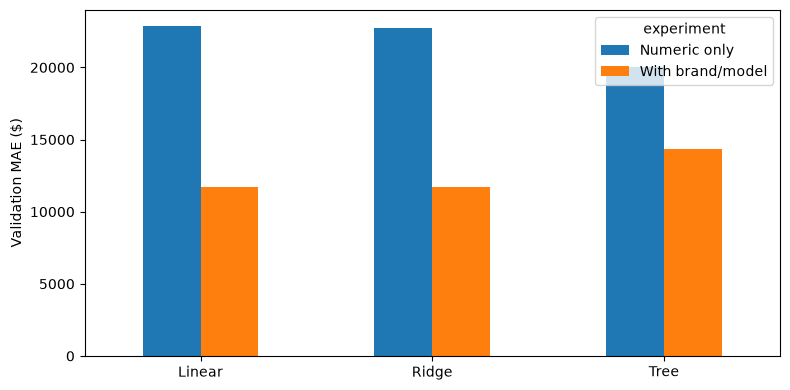

In [44]:
summary = pd.DataFrame(results)

comparison = summary.loc[
    summary["experiment"].isin(["numeric", "brand_model_onehot"])
    & summary["model"].isin(["Linear", "Ridge", "Tree"])
].pivot(
    index="model",
    columns="experiment",
    values="validation_MAE",
).rename(columns={
    "numeric": "Numeric only",
    "brand_model_onehot": "With brand/model",
})

comparison["Improvement (%)"] = (
    100
    * (comparison["Numeric only"] - comparison["With brand/model"])
    / comparison["Numeric only"]
)

display(comparison.round(2))

comparison[["Numeric only", "With brand/model"]].plot.bar(
    figsize=(8, 4), rot=0
)

plt.ylabel("Validation MAE ($)")
plt.xlabel("")
plt.tight_layout()
plt.show()

Гипотеза поддтвердилась, бренд и модель содержат полезную информацию, которую понять из пробега и года выпуска конечно нельзя

## Итоговая оценка методов
Сначала посмотрим на валидацию

In [45]:
summary = pd.DataFrame(results)

display(
    summary[[
        "experiment",
        "model",
        "train_MAE",
        "validation_MAE",
        "validation_MedAE",
        "MAE_std",
        "validation_RMSE",
        "validation_R2",
    ]]
    .sort_values("validation_MAE")
    .round(2)
)

,experiment,model,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2
35,selected_plus_engine_features_log,Ridge,3614.40,9248.35,3899.88,1426.29,28592.58,0.58
34,selected_plus_engine_features_log,Linear,3001.16,10056.71,4052.03,1737.35,32873.81,0.37
32,selected_plus_engine_features,Ridge,4507.74,11657.85,6014.00,1043.37,25490.39,0.73
5,brand_model_onehot,Ridge,4370.13,11692.21,5687.86,1202.92,25821.51,0.73
4,brand_model_onehot,Linear,3746.79,11714.97,5614.82,1219.79,26052.94,0.72
29,selected_plus_colors,Ridge,3599.42,12069.68,6547.82,1294.43,24979.65,0.75
17,raw_engine_onehot,Ridge,5779.04,12191.72,6665.94,777.94,26539.00,0.72
28,selected_plus_colors,Linear,2900.50,12192.88,6662.83,1386.78,25005.56,0.75
36,selected_plus_engine_features_log,Tree,1.29,12294.33,5393.40,1868.54,31096.17,0.61
20,raw_engine_rare_transmission,Ridge,5948.28,12309.02,6824.34,863.36,26137.60,0.73


Очень хорошо себя показала модель только с годом, пробегом, брендом и моделью, но извлеченные фичи мотора, а также предсказание логарифма вместо прямого немного добавило точности. Также лучшие Ridge и линейные оказались лучше деревьев. У нас много разряженных one hot олонок и немного числовых признаков, дерево может маленькие группы, в которых предсказания не так хорошо описывают новые данные.

Теперь прогоним тест для нашего лучшего метода

In [46]:
from sklearn.metrics import mean_absolute_error, median_absolute_error, root_mean_squared_error, r2_score

X_test = test_df.drop(columns="price").copy()
y_test = test_df["price"].copy()

engine = X_test["engine"].astype("string")

for feature, pattern in patterns.items():
    X_test[feature] = pd.to_numeric(
        engine.str.extract(pattern, expand=False),
        errors="coerce",
    ).astype(float)

alternative_cylinders = pd.to_numeric(
    engine.str.extract(
        r"(?i)(\d{1,2})\s*Cylinder",
        expand=False,
    ),
    errors="coerce",
).astype(float)

X_test["cylinders"] = X_test["cylinders"].fillna(
    alternative_cylinders
)

final_model = searches[
    ("selected_plus_engine_features_log", "Ridge")
].best_estimator_

predictions = final_model.predict(X_test)

test_results = pd.DataFrame([{
    "model": "Ridge + engine features + log target",
    "MAE": mean_absolute_error(y_test, predictions),
    "MedAE": median_absolute_error(y_test, predictions),
    "RMSE": root_mean_squared_error(y_test, predictions),
    "R2": r2_score(y_test, predictions),
}])

display(test_results.round(2))

,model,MAE,MedAE,RMSE,R2
0,Ridge + engine features + log target,16582.03,4008.64,137619.69,0.07


Медианная ошибка близка к результату кросс-валидации, но MAE получился значительно выше. Большой разрыв между MedAE, MAE и RMSE указывает на наличие очень крупных ошибок, сильно влияющих на итоговые метрики. Таким образом, типичная ошибка относительно стабильна, однако модель плохо справляется с некоторыми наблюдениями. Для понимания причин посмотрим на наибольшие ошибки.

In [47]:
error_analysis = test_df[
    ["brand", "model", "model_year", "milage", "price"]
].copy()

error_analysis["prediction"] = predictions
error_analysis["absolute_error"] = abs(y_test - predictions)

display(error_analysis.nlargest(10, "absolute_error"))

,brand,model,model_year,milage,price,prediction,absolute_error
693,Maserati,Quattroporte Base,2005,32000,2954083,18798.511183,2.935284e+06
229,Bugatti,Veyron 16.4 Grand Sport,2011,6330,1950995,37292.932114,1.913702e+06
3046,Porsche,Carrera GT Base,2005,4400,1599000,60673.583979,1.538326e+06
1061,Dodge,Viper GTC,2017,1389,489995,69055.411633,4.209396e+05
203,Ford,GT,2005,1897,429998,26339.472386,4.036585e+05
1811,Lamborghini,Aventador LP700-4,2016,3254,399900,226283.325625,1.736167e+05
1575,Mercedes-Benz,Maybach S 580 4MATIC,2022,4760,229000,68167.899069,1.608321e+05
3816,Rolls-Royce,Cullinan,2022,3420,399950,532207.277367,1.322573e+05
93,Aston,Martin DBS Superleggera,2021,2165,279950,173287.053465,1.066629e+05
450,Rolls-Royce,Ghost Base,2021,850,314900,210035.231001,1.048648e+05


Самые большие ошибки связаны с дорогими автомобилями. Три наблюдения с ценами от 1,6 до 3 млн дают почти половину суммарной абсолютной ошибки. При этом максимальная цена в обучающей выборке составляла около 750 тыс. Модель сохраняет относительно небольшую типичную ошибку, но плохо оценивает некоторые автомобили верхнего ценового сегмента.

## Дополнительно - более сильные модели
Это вне основной работы, просто интересно посмотреть насколько будет лучше

In [48]:
from sklearn.ensemble import RandomForestRegressor
from catboost import CatBoostRegressor

ensemble_numeric = numeric_features + engine_features
ensemble_categorical = ["brand", "model"]

ensemble_results = []
ensemble_searches = {}

In [54]:
def evaluate_ensemble(name, estimator, param_grid, X, log_target=False, fit_params=None):
    if log_target:
        estimator = TransformedTargetRegressor(
            regressor=estimator,
            func=np.log1p,
            inverse_func=np.expm1,
        )

        param_grid = {
            f"regressor__{key}": values
            for key, values in param_grid.items()
        }

    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring=scoring,
        refit="MAE",
        cv=cv,
        return_train_score=True,
        n_jobs=1,
        error_score="raise",
    )

    search.fit(X, y_train, **(fit_params or {}))

    best = search.best_index_
    scores = search.cv_results_

    row = {
        "model": name,
        "target": "log" if log_target else "direct",
        "train_MAE": -scores["mean_train_MAE"][best],
        "validation_MAE": -scores["mean_test_MAE"][best],
        "validation_MedAE": -scores["mean_test_MedAE"][best],
        "MAE_std": scores["std_test_MAE"][best],
        "validation_RMSE": -scores["mean_test_RMSE"][best],
        "validation_R2": scores["mean_test_R2"][best],
        "best_params": search.best_params_,
    }

    ensemble_results[:] = [
        item for item in ensemble_results
        if (item["model"], item["target"])
        != (row["model"], row["target"])
    ]

    ensemble_results.append(row)
    ensemble_searches[(name, row["target"])] = search

    return pd.DataFrame([row])

In [55]:
forest_pipeline = Pipeline([
    ("preprocessing", make_preprocessor(
        numeric=ensemble_numeric,
        categorical=ensemble_categorical,
        encoding="onehot",
        scale=False,
    )),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])

forest_grid = {
    "model__max_depth": [15, None],
    "model__min_samples_leaf": [1, 5],
    "model__max_features": [0.7, 1.0],
}

for log_target in [False, True]:
    display(evaluate_ensemble(
        name="Random Forest",
        estimator=clone(forest_pipeline),
        param_grid=forest_grid,
        X=X_train,
        log_target=log_target,
    ))

,model,target,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,Random Forest,direct,3484.98233,9520.762764,4250.452,1261.489278,23656.657092,0.779197,"{'model__max_depth': None, 'model__max_feature..."


,model,target,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,Random Forest,log,4001.724346,10015.78512,4157.381206,1642.67174,27149.953369,0.712907,"{'regressor__model__max_depth': None, 'regress..."


In [56]:
X_catboost = X_train[
    ensemble_numeric + ensemble_categorical
].copy()

for column in ensemble_categorical:
    X_catboost[column] = (
        X_catboost[column]
        .astype("string")
        .fillna("Unknown")
        .astype(str)
    )

for column in ensemble_numeric:
    X_catboost[column] = X_catboost[column].astype(float)

In [57]:
catboost_model = CatBoostRegressor(
    loss_function="RMSE",
    learning_rate=0.05,
    random_seed=RANDOM_STATE,
    verbose=False,
    allow_writing_files=False,
    thread_count=4,
)

catboost_grid = {
    "depth": [4, 6],
    "iterations": [500, 1000],
    "l2_leaf_reg": [3, 10],
}

for log_target in [False, True]:
    display(evaluate_ensemble(
        name="CatBoost",
        estimator=clone(catboost_model),
        param_grid=catboost_grid,
        X=X_catboost,
        log_target=log_target,
        fit_params={
            "cat_features": ensemble_categorical,
        },
    ))

,model,target,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,CatBoost,direct,5949.823259,9325.974858,4283.187601,1161.925444,22619.656571,0.795959,"{'depth': 6, 'iterations': 1000, 'l2_leaf_reg'..."


,model,target,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
0,CatBoost,log,5993.549038,8558.482264,3811.602478,1232.564715,22836.212777,0.793621,"{'regressor__depth': 6, 'regressor__iterations..."


,model,target,train_MAE,validation_MAE,validation_MedAE,MAE_std,validation_RMSE,validation_R2,best_params
3,CatBoost,log,5993.55,8558.48,3811.60,1232.56,22836.21,0.79,"{'regressor__depth': 6, 'regressor__iterations..."
2,CatBoost,direct,5949.82,9325.97,4283.19,1161.93,22619.66,0.80,"{'depth': 6, 'iterations': 1000, 'l2_leaf_reg'..."
0,Random Forest,direct,3484.98,9520.76,4250.45,1261.49,23656.66,0.78,"{'model__max_depth': None, 'model__max_feature..."
1,Random Forest,log,4001.72,10015.79,4157.38,1642.67,27149.95,0.71,"{'regressor__model__max_depth': None, 'regress..."


,model,target,validation_MAE,validation_MedAE,validation_RMSE,validation_R2
6,CatBoost,log,8558.48,3811.60,22836.21,0.79
4,Ridge,log,9248.35,3899.88,28592.58,0.58
7,CatBoost,direct,9325.97,4283.19,22619.66,0.80
8,Random Forest,direct,9520.76,4250.45,23656.66,0.78
9,Random Forest,log,10015.79,4157.38,27149.95,0.71
3,Linear,log,10056.71,4052.03,32873.81,0.37
1,Ridge,direct,11657.85,6014.00,25490.39,0.73
5,Tree,log,12294.33,5393.40,31096.17,0.61
0,Linear,direct,12412.10,6160.63,26519.17,0.71
2,Tree,direct,12783.16,5716.40,30331.54,0.60


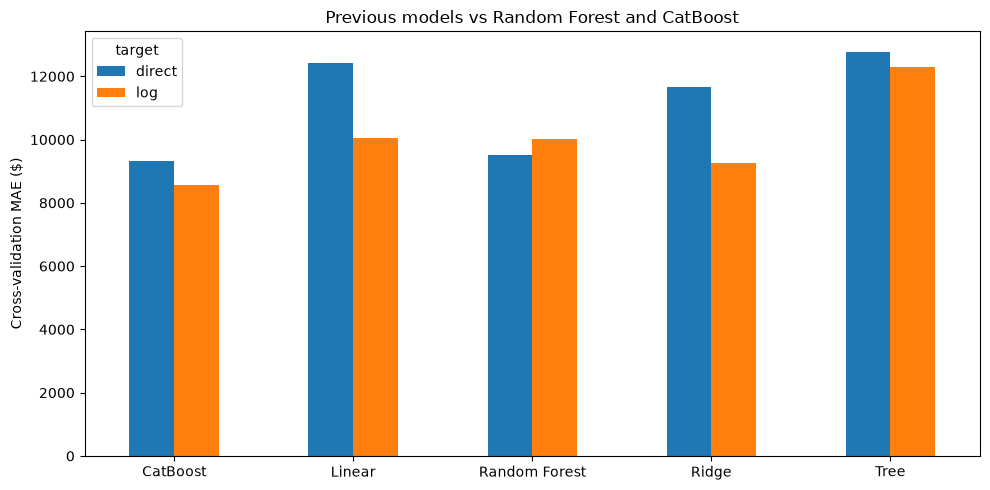

In [59]:
ensemble_summary = (
    pd.DataFrame(ensemble_results)
    .sort_values("validation_MAE")
)

display(ensemble_summary.round(2))

previous = pd.DataFrame(results)

previous = previous.loc[
    previous["experiment"].isin([
        "selected_plus_engine_features",
        "selected_plus_engine_features_log",
    ])
].copy()

previous["target"] = previous["experiment"].map({
    "selected_plus_engine_features": "direct",
    "selected_plus_engine_features_log": "log",
})

comparison = pd.concat([
    previous[[
        "model", "target", "validation_MAE",
        "validation_MedAE", "validation_RMSE", "validation_R2",
    ]],
    ensemble_summary[[
        "model", "target", "validation_MAE",
        "validation_MedAE", "validation_RMSE", "validation_R2",
    ]],
], ignore_index=True)

display(comparison.sort_values("validation_MAE").round(2))

comparison.pivot(
    index="model",
    columns="target",
    values="validation_MAE",
).plot.bar(figsize=(10, 5), rot=0)

plt.ylabel("Cross-validation MAE ($)")
plt.xlabel("")
plt.title("Previous models vs Random Forest and CatBoost")
plt.tight_layout()
plt.show()